# Как слово становится вектором, а последовательность — переводом
**Париж − Франция + Италия = ?** Запишем, что именно вычитается, где ищется слово-ответ и какую роль играет корпус. Затем попробуем переставить два слова в предложении. Этот опыт приведёт от одной точки на слово к состоянию, которое меняется при чтении. В конце обучим маленький переводчик и проследим один перевод по шагам.

In [ ]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA
from torch import nn
from torch.nn import functional as F

torch.manual_seed(13)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "axes.titlelocation": "left"})
blue, red = "#205f73", "#aa4937"

## Какие задачи решают по тексту?

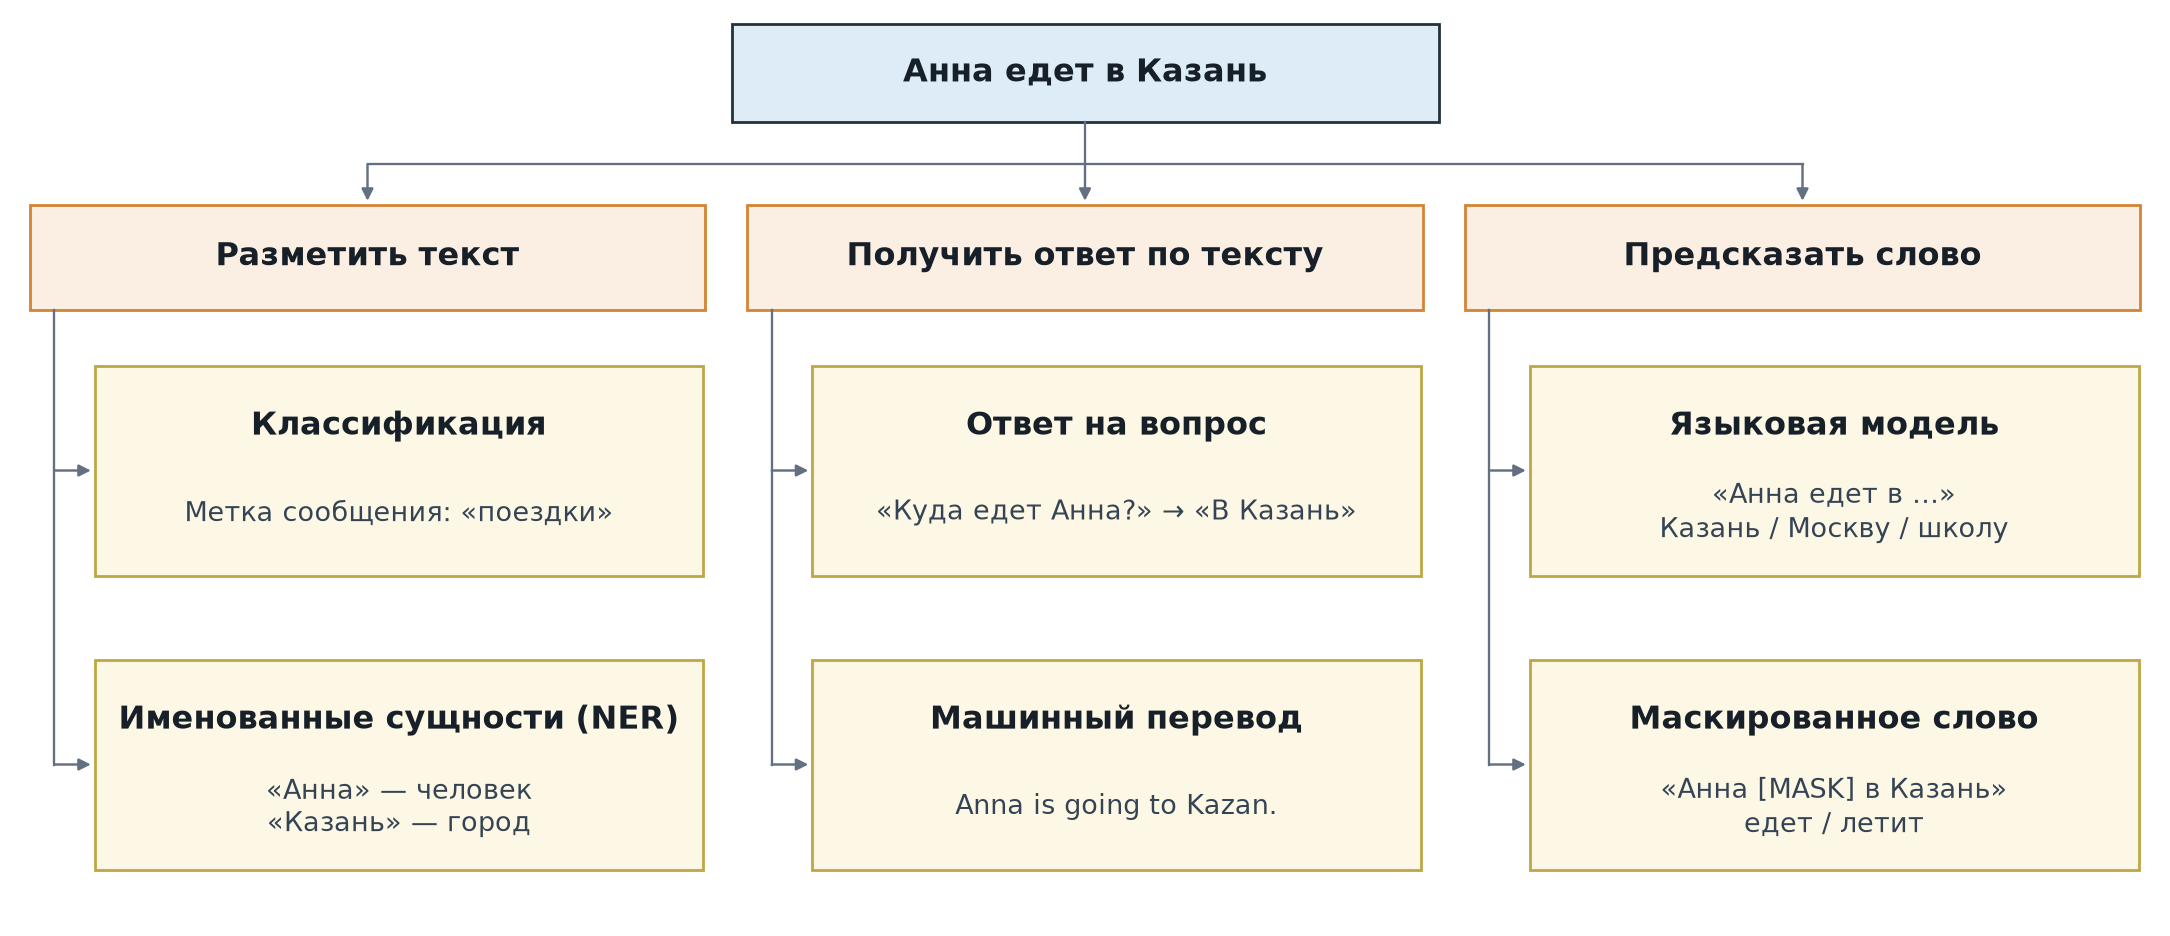

Сравните два примера справа. Какие слова видит модель, когда выбирает продолжение? Что дополнительно известно ей при восстановлении пропуска?

В HW2 модель присваивала метку целому диалогу. Для генерации понадобится много предсказаний, по одному после каждого прочитанного фрагмента. Начнём с общего для обеих задач вопроса: какие числа подать на вход вместо слова?

### Что мешок слов из HW2 теряет при чтении?
«Петя догнал такси» и «Такси догнало Петю» после лемматизации состоят из одинаковых слов. Посчитаем числа вхождений. Какому столбцу соответствует тот, кто кого догнал?

In [ ]:
from collections import Counter
phrases = [["петя", "догнать", "такси"], ["такси", "догнать", "петя"]]
pd.DataFrame([Counter(words) for words in phrases],
             index=["Петя догнал такси", "Такси догнало Петю"])

При одинаковом наборе лемм TF-IDF по отдельным словам тоже совпадёт. Позже проследим, как рекуррентная сеть реагирует на перестановку слов. Сначала разберём другую трудность: если заменить «такси» на «автобус», как модели передать близость двух разных слов?

## 1. Что значит «слово в N-мерном пространстве»?

$V$ — число слов в словаре. **$N$ — число координат в векторе одного слова**, или размерность эмбеддинга. Мы выбираем $N$ при создании модели. В примере ниже шесть слов ($V=6$), и каждое описываем тремя числами ($N=3$). Например, вектор слова «кот» равен $(1.0,\;0.8,\;0.1)$.

Сложим векторы в таблицу $E$. Получится $V$ строк, по одной на слово, и $N$ столбцов, по одному на координату. Присвоим словам индексы от $0$ до $V-1$. Чтобы получить вектор слова с индексом $j$, берём строку $E_j$. Умножение $e_j^\top E$ выбирает ту же строку: в one-hot векторе $e_j$ длины $V$ единица стоит на месте $j$, а остальные элементы равны нулю.

У двух разных one-hot векторов скалярное произведение всегда равно нулю. В таблице $E$ близость слов зависит от значений координат. Здесь мы задали их вручную, а при обучении эмбеддингов эти значения подбирает модель.

In [ ]:
words = ["кот", "пёс", "догнать", "спать", "город", "дом"]
E = torch.tensor([[1., .8, .1], [.9, 1., .1], [.1, .3, 1.],
                  [.1, .1, .9], [.1, -.8, .1], [.2, -.7, 0.]])
layer = nn.Embedding.from_pretrained(E)
ids = torch.tensor([0, 1, 4])
assert torch.equal(F.one_hot(ids, len(words)).float() @ E, layer(ids))
pd.DataFrame(layer(ids).numpy(), index=[words[i] for i in ids], columns=["x1", "x2", "x3"])

Почему «кот» и «пёс» оказались рядом? Мы сами записали им почти одинаковые строки. Другая таблица тех же размеров могла бы поместить «кота» рядом с «домом». По одному индексу слова выбрать координаты невозможно. Нужны наблюдения из текста, по которым можно проверить, удачны ли векторы. Возьмём для этого соседние слова.

## 2. Word2vec: как выучить вектор слова по его соседям?

**Word2vec — семейство моделей, которые учат векторы слов на их соседстве в тексте. CBOW и Skip-gram — две архитектуры Word2vec. Для обучения выбирают одну из них.** У обеих одна цель: получить таблицу векторов $E$, в которой у каждого слова есть своя строка. Различается учебное задание. CBOW угадывает слово по его соседям, а Skip-gram по слову угадывает соседей. Ошибка в этих предсказаниях даёт градиент, который обновляет векторы.

Прочитаем «утром кот **спал** на тёплом подоконнике». Остановимся на позиции «спал». Слово на выбранной позиции назовём **центром**, а слова в окне вокруг неё — **контекстом**. При радиусе 2 в контекст попадают «утром», «кот», «на» и «тёплом». Теперь передвинем окно на «кот». Он стал центром, а «спал» вошло в его контекст. Роль определяется положением окна.

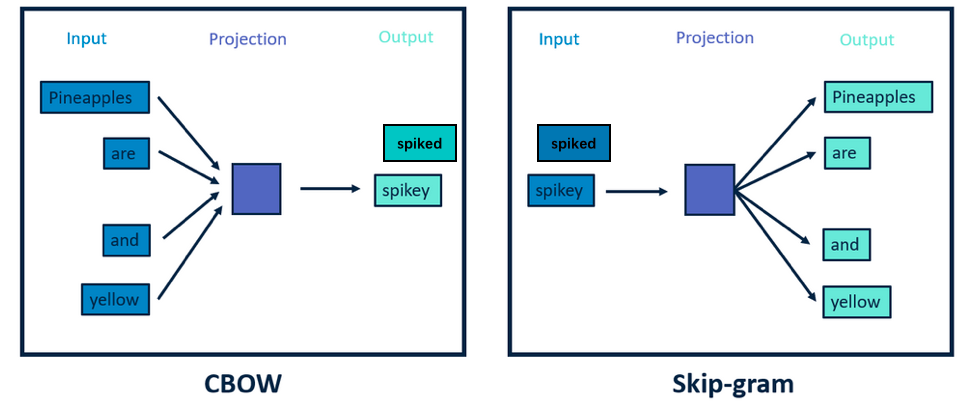

Прочитаем обе панели слева направо. Возьмём фразу «Pineapples are **spikey** and yellow». В центре окна стоит слово *spikey* («колючие»). По обе стороны от него лежат по два слова. Дополнительная надпись *spiked* на схеме обозначает ту же позицию. В этом примере используем одно написание — *spikey*.

**Слева — CBOW (Continuous Bag of Words).** Закроем *spikey*. На входе останутся *Pineapples*, *are*, *and*, *yellow*. Возьмём четыре строки таблицы эмбеддингов и усредним их по координатам. Фиолетовый квадрат — полученный вектор контекста. По нему модель оценивает слова словаря, а правильный ответ для этого окна — *spikey*. Если переставить соседей местами, среднее останется тем же. Отсюда «мешок слов» в названии.

**Справа — Skip-gram.** Теперь открыто только *spikey*. Фиолетовый квадрат — его собственный вектор из таблицы эмбеддингов. Каждая стрелка задаёт отдельную обучающую пару с этим центром: (*spikey*, *Pineapples*), (*spikey*, *are*), (*spikey*, *and*), (*spikey*, *yellow*). У всех четырёх пар один вход. При обучении модель получает сигнал повысить оценку каждого из этих соседей.

### Как по слову найти его вектор?

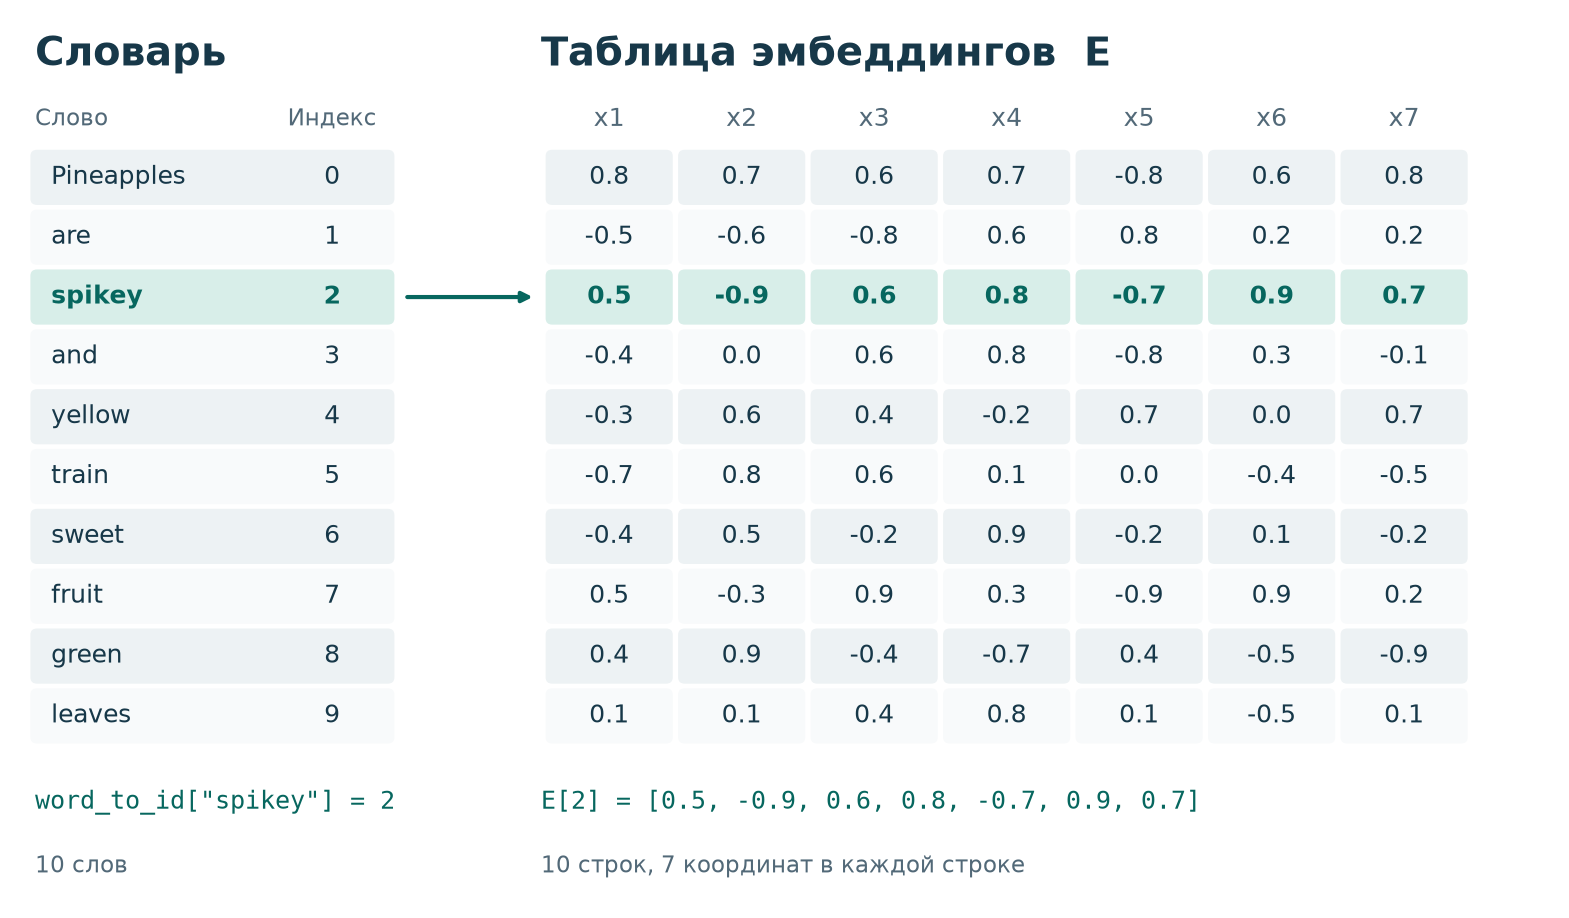

У слова *spikey* индекс 2. По этому индексу выбираем третью строку таблицы $E$ целиком: все семь чисел образуют один вектор. Во время обучения значения в строке меняются, а индекс слова остаётся прежним.

Для расчёта CBOW и Skip-gram ниже возьмём меньший пример: первые шесть слов и по две координаты на слово. Пара *spikey → yellow* получает индексы 2 и 4.

In [ ]:
window_words = ["Pineapples", "are", "spikey", "and", "yellow", "train"]
word_to_id = {word: i for i, word in enumerate(window_words)}
pd.DataFrame({"слово": window_words}).rename_axis("индекс")

In [ ]:
input_start = torch.tensor([[2., 0.], [1., 1.], [0., 1.], [0., 0.], [1., -1.], [-1., 0.]])
center_id = word_to_id["spikey"]
neighbor_ids = torch.tensor([word_to_id[w] for w in ["Pineapples", "are", "and", "yellow"]])

def skip_projection(embeddings):
    return embeddings[center_id]

def cbow_projection(embeddings):
    return embeddings[neighbor_ids].mean(dim=0)

skip_hidden = skip_projection(input_start)
cbow_hidden = cbow_projection(input_start)
print("Skip-gram:", skip_hidden.tolist(), "   CBOW:", cbow_hidden.tolist())

### Выходной слой: какой логит получит yellow?

Выходные веса образуют отдельную таблицу $U$. Её строка $u_w$ содержит два веса для кандидата $w$. Для пары *spikey → yellow* входной вектор уже найден: $h=(0,1)$. Возьмём выходные веса слова *yellow*, $u_{\rm yellow}=(0,-1)$. Логит этого ответа равен $s_{\rm yellow}=u_{\rm yellow}^\top h=0\cdot0+(-1)\cdot1=-1$.

Операция $U h$ выполняет такой расчёт для всех шести кандидатов сразу. Softmax переводит шесть логитов в одно распределение: $p(w\mid h)=\exp(s_w)/\sum_j\exp(s_j)$. Для всех стрелок из *spikey* распределение одно и то же. Стрелка показывает, какую строку взять за правильный ответ при подсчёте потери.

In [ ]:
output_start = torch.tensor([[0., 1.], [0., 0.], [1., 0.], [0., 0.], [0., -1.], [-1., 0.]])
skip_logits = output_start @ skip_hidden
cbow_logits = output_start @ cbow_hidden
skip_probs = skip_logits.softmax(dim=0)
cbow_probs = cbow_logits.softmax(dim=0)
pd.DataFrame({"логит Skip-gram": skip_logits, "P Skip-gram": skip_probs,
              "логит CBOW": cbow_logits, "P CBOW": cbow_probs}, index=window_words).round(3)

### За какой ответ начисляется ошибка?

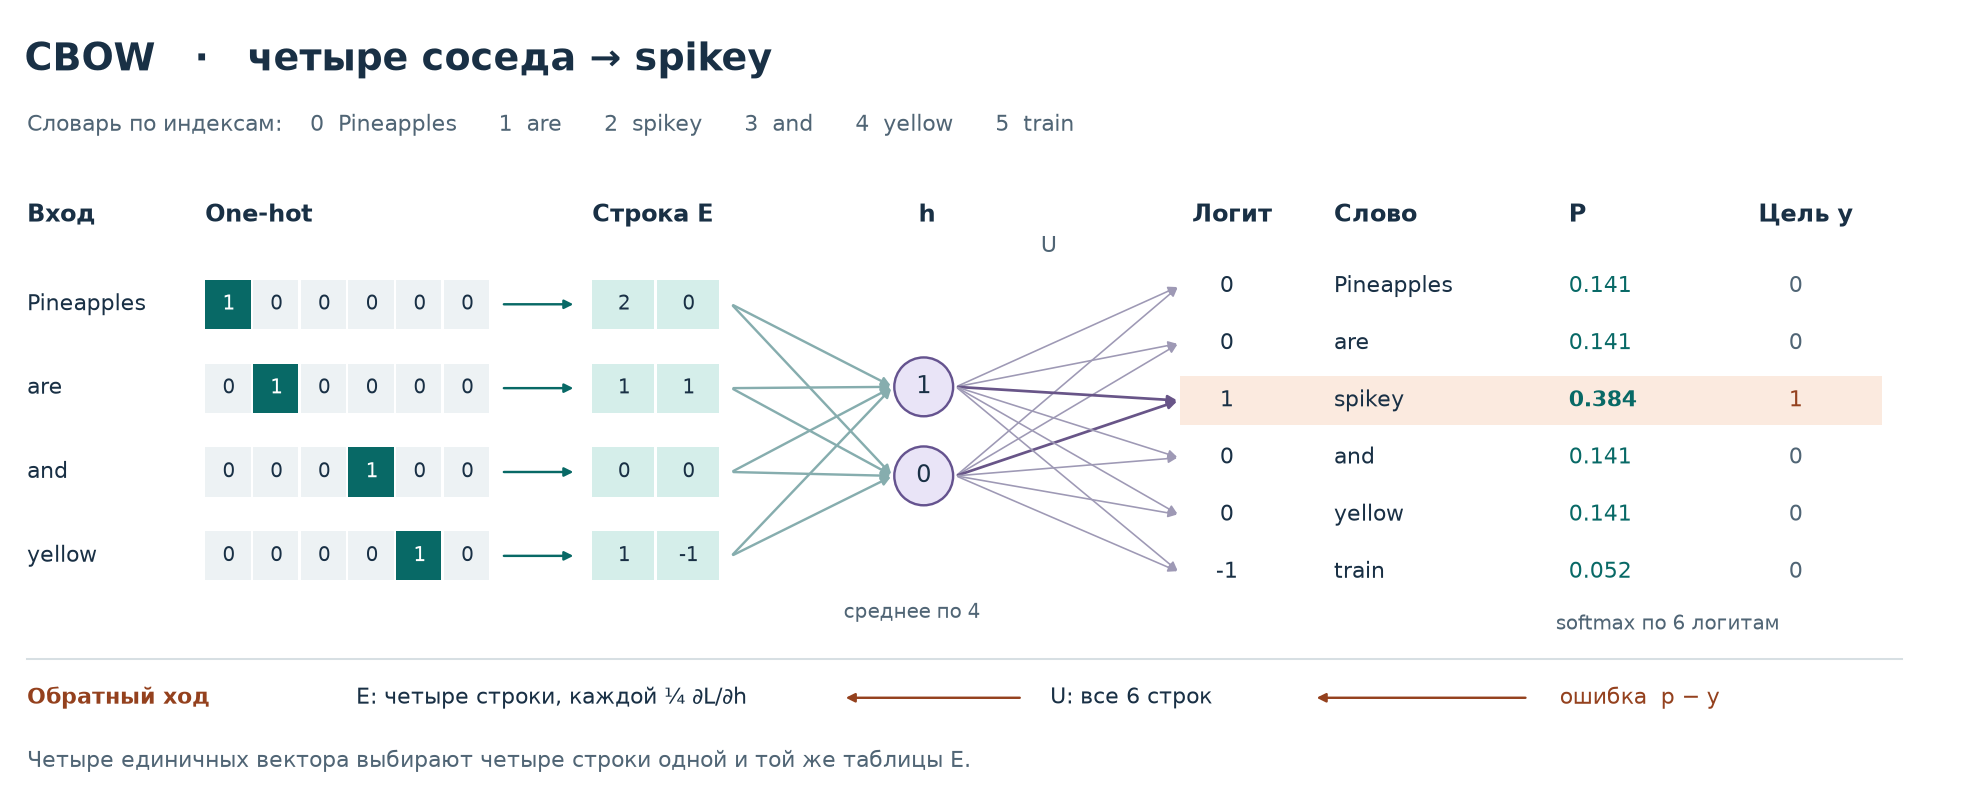

**CBOW.** Среднее четырёх синих векторов равно $h=(1,0)$. У правильного слова *spikey* выходной вектор $(1,0)$, поэтому его оценка равна $1$. У слова *train* оценка $-1$, у остальных четырёх — $0$. Вероятность правильного ответа равна $e/(e+4+e^{-1})\approx0.384$. Потеря для окна — минус логарифм этой вероятности: $L_{\rm CBOW}=-\ln p(\mathrm{spikey}\mid h)\approx0.96$. Чем выше вероятность *spikey*, тем меньше потеря.

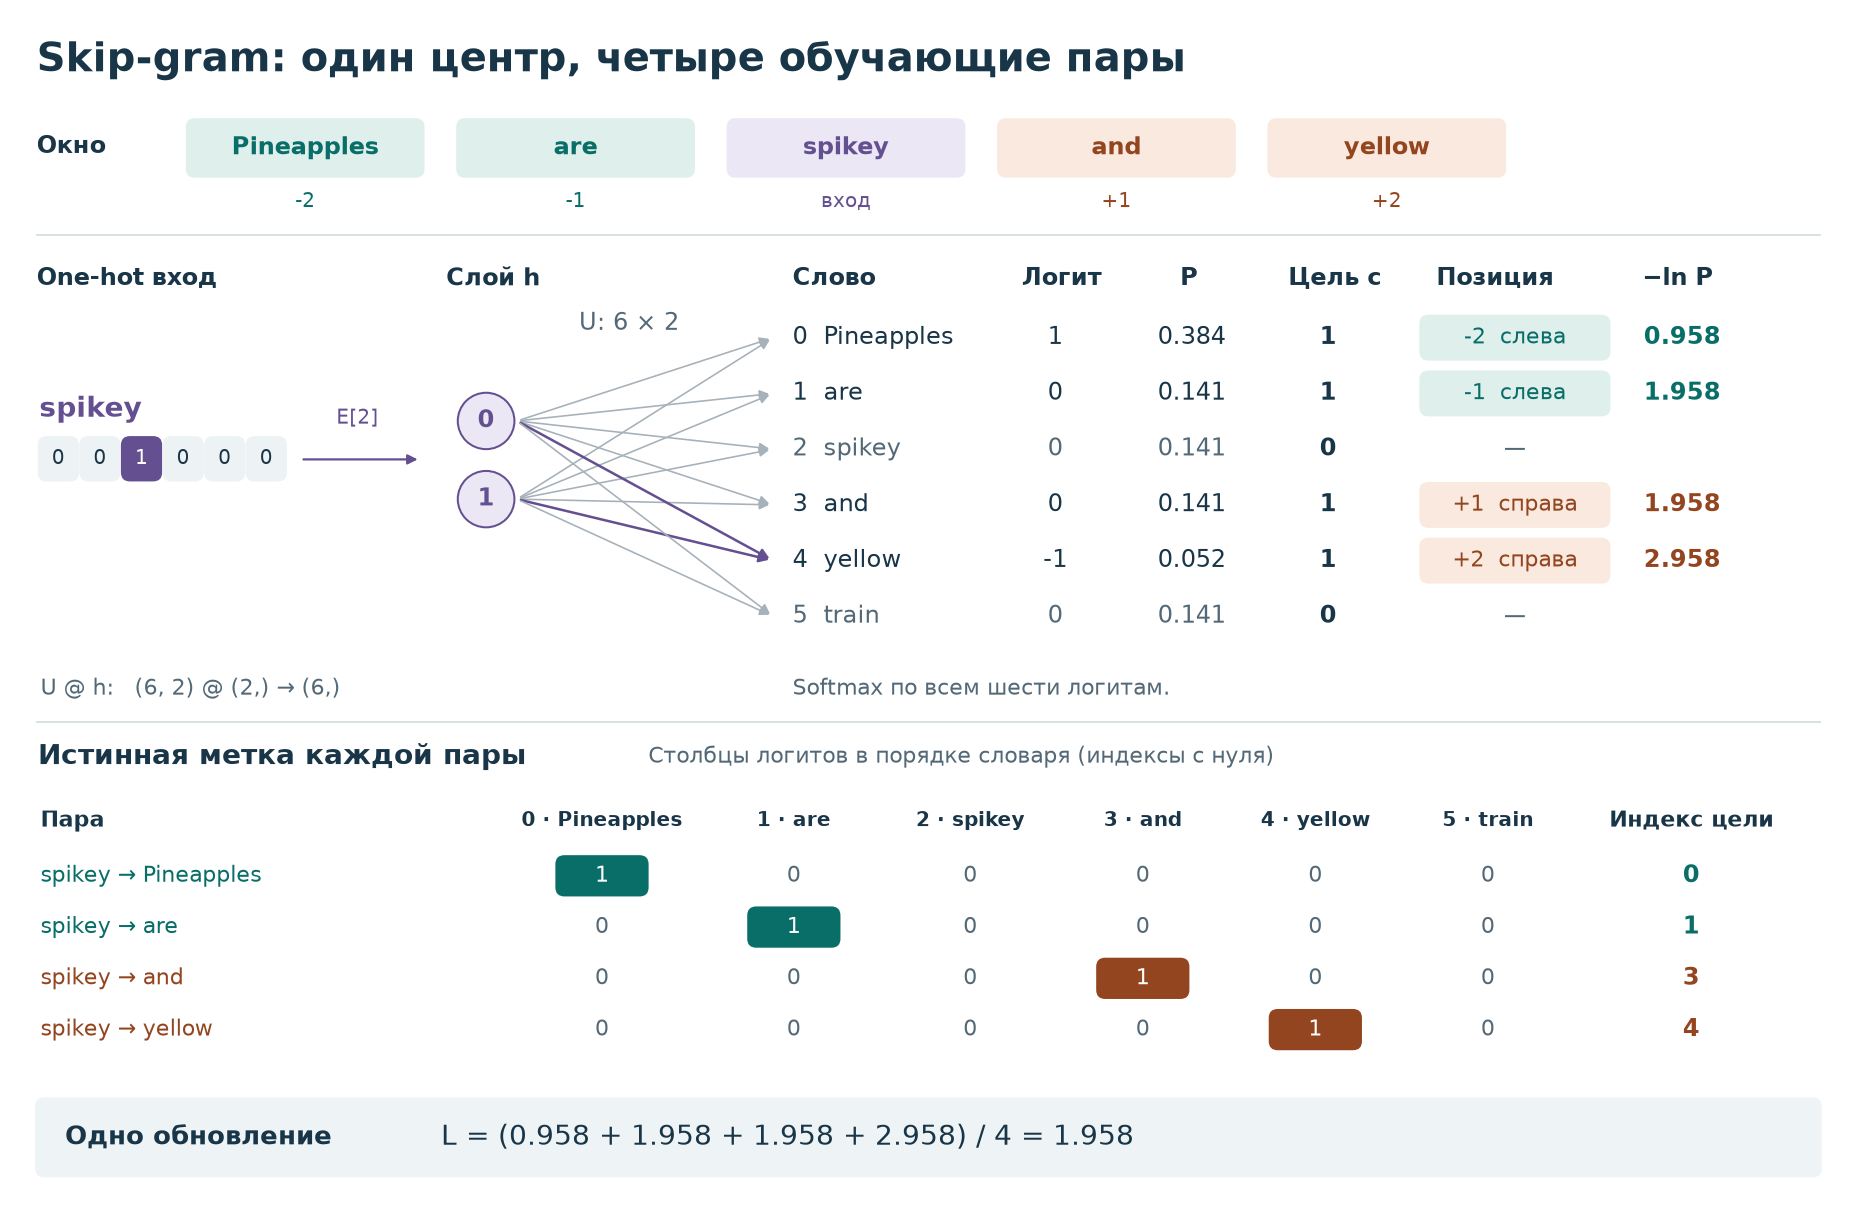

**Skip-gram.** У выходной матрицы $U$ форма $(6,2)$: каждая из шести строк хранит два веса для одного слова. Вектор $U h$ содержит шесть логитов в порядке словаря. Для четырёх пар индексы целей равны `[0, 1, 3, 4]`. В строке пары (*spikey*, *yellow*) единица стоит в столбце 4 (пятом по счёту). Сеть получает *spikey*, выбирает его вектор $h=(0,1)$ и выдаёт шесть логитов. У *yellow* логит равен $-1$, а вероятность после softmax — примерно $0.052$. В исходной фразе *yellow* стоит на два слова правее центра. Поэтому для пары (*spikey*, *yellow*) берём именно эту вероятность. Её вклад в потерю равен $-\ln p(\mathrm{yellow}\mid\mathrm{spikey})\approx 2.958$.

Столбец $c$ на верхней схеме получается сложением четырёх строк нижней таблицы. Он показывает, сколько раз каждое слово стало целью в окне: `[1, 1, 0, 1, 1, 0]`. Для средней потери делим счётчики на 4. Получаем целевое распределение `[0.25, 0.25, 0, 0.25, 0.25, 0]`, с которым сравниваем прогноз softmax. Если сосед встретится дважды, его счётчик будет равен 2.

Теперь проследим остальные три цветные строки. Для целей *Pineapples*, *are* и *and* берём вероятности из того же прогноза. Позиции −2, −1, +1 и +2 нужны для выбора соседей из текста. В этом примере у сети один выход по словарю, а при обучении — четыре пары. Усредняем их потери и делаем один шаг оптимизатора.

[Видео с пошаговым разбором обеих архитектур — The Semicolon, Word2Vec – Skipgram and CBOW](https://www.youtube.com/watch?v=UqRCEmrv1gQ&t=250s).

In [ ]:
# При фиксированных весах прогноз для центра вычислен один раз.
loss_per_neighbor = -skip_logits.log_softmax(dim=0)[neighbor_ids]
window_loss = loss_per_neighbor.mean()
neighbor_counts = torch.bincount(neighbor_ids, minlength=len(window_words))
target_distribution = neighbor_counts / len(neighbor_ids)
loss_from_counts = -(target_distribution * skip_logits.log_softmax(dim=0)).sum()
assert torch.allclose(window_loss, loss_from_counts)
display(pd.DataFrame({
    "позиция относительно spikey": [-2, -1, 1, 2],
    "целевой сосед": [window_words[i] for i in neighbor_ids],
    "вероятность цели": skip_probs[neighbor_ids],
    "потеря пары": loss_per_neighbor,
}).round(3))
print(f"Средняя потеря окна: {window_loss.item():.3f}")

### Как один шаг CBOW обновляет веса?

Ответ известен из текста: на месте пропуска стояло *spikey*. У него индекс 2, поэтому в векторе цели $y$ единица стоит на третьей позиции. Модель отвела этому слову лишь $p_2=0.384$. Для softmax с кросс-энтропией производная потери по каждому логиту равна $\delta_j=p_j-y_j$. У правильного слова она отрицательна: если поднять его логит, потеря уменьшится.

Проследим две координаты весов при скорости обучения $\eta=0.3$. Обе производные считаем по весам **до** шага.

- **Выходная таблица $U$.** Логит слова $j$ равен $s_j=u_j^\top h$, поэтому $\partial L/\partial u_j=\delta_j h$. У слова *spikey* первая координата меняется с $1$ до $1.185$. Остальные слова тоже участвовали в softmax: для каждого из них $y_j=0$, а поправка определяется его $p_j$.
- **Входная таблица $E$.** Собираем вклады всех логитов в градиент контекста: $\partial L/\partial h=U^\top\delta$. Первая координата этого градиента равна $-0.668$ с точностью до округления. Поскольку $h$ — среднее четырёх векторов, каждый сосед получает четверть градиента. Поэтому первая координата входного вектора *are* меняется с $1$ до $1.050$.

В коде ниже `backward()` вычисляет эти производные, а `step()` обновляет обе таблицы. Для сравнения сделаем шаг Skip-gram из тех же начальных весов: там четыре потери дают градиент одной входной строке *spikey*.

In [ ]:
def train_window(project, target_ids, steps=1):
    input_vectors = nn.Parameter(input_start.clone())
    output_vectors = nn.Parameter(output_start.clone())
    optimizer = torch.optim.SGD([input_vectors, output_vectors], lr=0.3)

    def window_loss():
        hidden = project(input_vectors)
        logits = output_vectors @ hidden
        log_probs = logits.log_softmax(dim=0)
        return -log_probs[target_ids].mean()

    before = window_loss().item()
    for _ in range(steps):
        optimizer.zero_grad()
        loss = window_loss()
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        after = window_loss()
        changed = (input_vectors != input_start).any(dim=1)
    changed_words = [word for word, flag in zip(window_words, changed) if flag]
    summary = before, after.item(), ", ".join(changed_words)
    return summary, input_vectors.detach(), output_vectors.detach()


cbow_step, _, _ = train_window(cbow_projection, torch.tensor([center_id]))
skip_step, _, _ = train_window(skip_projection, neighbor_ids)
pd.DataFrame([cbow_step, skip_step], index=["CBOW", "Skip-gram"],
             columns=["потеря до шага", "потеря после шага", "изменившиеся строки E"]).round(3)

In [ ]:
_, cbow_input, cbow_output = train_window(cbow_projection, torch.tensor([center_id]), steps=60)
_, skip_input, skip_output = train_window(skip_projection, neighbor_ids, steps=60)

# Строка spikey в двух таблицах после обучения на одном окне.
pd.DataFrame([cbow_input[center_id].tolist() + cbow_output[center_id].tolist(),
              skip_input[center_id].tolist() + skip_output[center_id].tolist()],
             index=["CBOW", "Skip-gram"], columns=["v₁", "v₂", "u₁", "u₂"]).round(2)

Теперь сдвинем окно вправо на одно слово. Центром станет *and*, а *spikey* окажется в контексте. CBOW будет угадывать *and*, Skip-gram — его соседей. Обе модели продолжают обучение с обновлёнными таблицами. Так одно и то же слово за время прохода по корпусу успевает побыть и входом, и целью.

## 3. Ближайшие слова и разности векторов
Теперь возьмём готовые векторы Word2vec из английской выборки NLTK. Вместо двух координат учебного примера у каждого слова здесь 300. Ближайшие слова ищем среди слов этой выборки.

Косинус $\cos(a,b)=a^\top b/(\|a\|\,\|b\|)$ сравнивает направления. Разность $v_b-v_a$ задаёт смещение из точки $a$ в точку $b$. Гипотеза аналогии: если перенести это смещение в точку $c$, рядом окажется слово с похожим отношением к $c$. Для перехода «мужчина → король» и начала «женщина» это $q=v_{woman}+(v_{king}-v_{man})$. Нормируем векторы слов до сложения и запрос после него. Ответ ищем среди остальных слов. [Данные NLTK](https://github.com/nltk/nltk_data/blob/gh-pages/packages/models/word2vec_sample.zip)

In [ ]:
bundle = np.load(Path("data") / "word_vectors.npz")
vocab = bundle["words"].tolist()
vectors = bundle["vectors"].astype("float32")
vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)
index = {w: i for i, w in enumerate(vocab)}
print(vectors.shape, "— слова и координаты")

In [ ]:
def nearest(query, exclude=(), k=5):
    scores = vectors @ (query / np.linalg.norm(query))
    scores[[index[w] for w in exclude]] = -np.inf
    best = np.argsort(-scores)[:k]
    return pd.Series(scores[best], index=[vocab[i] for i in best], name="косинус")

def analogy(a, b, c):
    query = vectors[index[b]] - vectors[index[a]] + vectors[index[c]]
    return nearest(query, [a, b, c])

display(nearest(vectors[index["king"]], ["king"]))
for a, b, c in [("man", "king", "woman"), ("France", "Paris", "Italy"),
                ("man", "king", "cat")]:
    print(f"{b} - {a} + {c}")
    display(analogy(a, b, c).to_frame().round(3))

Последний запрос проверяет границы аналогии. Косинус всегда выдаст победителя, даже когда отношение лишено ясного смысла. Есть и другая трудность: один статический вектор объединяет все употребления слова. Например, английское *bank* встречается и в разговорах о деньгах, и в описаниях берега.

### Что делает знак минус?
Разберём арифметику на плоскости. В условных координатах Франция лежит в $(1,1)$, Париж в $(1,3)$, Италия в $(4,0)$. Тогда смещение «страна → столица» равно $(1,3)-(1,1)=(0,2)$. Прибавим его к Италии: $(4,0)+(0,2)=(4,2)$. Это координаты запроса; целевой вектор может вообще отсутствовать в словаре. На реальных данных сравним два поиска: ближайших к Италии и ближайших к Италии со смещением.

In [ ]:
country = vectors[index["Italy"]]
offset = vectors[index["Paris"]] - vectors[index["France"]]
plain = nearest(country, ["Italy"])
shifted = nearest(country + offset, ["Italy", "Paris", "France"])
pd.DataFrame({"от Италии": plain.index, "косинус": plain.round(3).values,
              "после переноса": shifted.index, "новый косинус": shifted.round(3).values},
             index=range(1, 6))

In [ ]:
pairs = [("man", "king"), ("woman", "queen"), ("France", "Paris"), ("Italy", "Rome")]
names = [w for pair in pairs for w in pair]
projection = PCA(n_components=2)
xy = projection.fit_transform(vectors[[index[w] for w in names]])
fig, ax = plt.subplots(figsize=(8, 4.6))
for j, (a, b) in enumerate(pairs):
    start, end = xy[2*j:2*j+2]
    color = blue if j < 2 else red
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", color=color, lw=2))
    for word, point in [(a, start), (b, end)]:
        ax.scatter(*point, color=color)
        offsets = {"man": (-38, 14), "woman": (9, 7), "king": (-36, -11), "queen": (10, 6),
                   "France": (13, 15), "Italy": (10, 31), "Paris": (15, -18), "Rome": (-40, -10)}
        ax.annotate(word, point, xytext=offsets[word], textcoords="offset points",
                    arrowprops=dict(arrowstyle="-", lw=.6, color=color))
ax.margins(.23)
ax.set(xlabel="Первая компонента", ylabel="Вторая компонента",
       title="Проекция четырёх переносов из 300 измерений")
ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
plt.show()

PCA подбирает плоскость по этим восьми словам. Она теряет часть расстояний и углов. Таблица выше ищет соседей в исходных 300 координатах. По двум стрелкам на плоскости восстановить этот рейтинг нельзя.

In [ ]:
# Сумма двух слов. Ищем соседей в исходных 300 измерениях, исключая сами слагаемые.
rows = []
for word in ["king", "man"]:
    neighbors = nearest(vectors[index[word]] + vectors[index["Italy"]], [word, "Italy"])
    for rank, (neighbor, cosine) in enumerate(neighbors.items(), start=1):
        rows.append([word + " + Italy", rank, neighbor, cosine])
pd.DataFrame(rows, columns=["Сумма", "Место", "Сосед", "Косинус"]).round(3)

## 4. Как прочитать фразу по одному слову?

«Утром кот догнал пса дома» и «Утром пёс догнал кота дома». Если привести слова к начальной форме и сложить их эмбеддинги, обе фразы дадут одну сумму. А ответ на вопрос «кто кого догнал?» зависит от порядка.

Прочитаем первое слово. Пусть $x_1$ — его вектор. Сохраним результат обработки в векторе $h_1=\tanh(W_x x_1+b)$. На втором слове у нас уже есть что вспомнить. К вкладу нового слова прибавим преобразованное состояние первого шага:
$$h_2=\tanh(W_x x_2+W_h h_1+b).$$

На третьем шаге подставим $x_3$ и $h_2$. Чтобы и первое слово обрабатывать по той же формуле, зададим начальное состояние $h_0$. Возьмём вектор нулей: до первого слова сеть ничего не прочла. Можно также обучать общее начальное состояние. Случайная инициализация весов и выбор $h_0$ — отдельные решения.

Так устроена **рекуррентная нейронная сеть (RNN)**: $h_t=\tanh(W_x x_t+W_h h_{t-1}+b)$. Размер состояния постоянен, а матрицы $W_x,W_h$ общие для всех шагов.

Оставим одну координату и зададим веса вручную, чтобы проследить эффект порядка. Слова «кот» и «пёс» внесут $+1$ и $-1$, остальные — ноль. На каждом шаге вычислим $h_t=\tanh(x_t+0.7h_{t-1})$. После «утром кот» получим $\tanh(1)\approx0.76$. После «утром пёс» знак будет противоположным.

In [ ]:
phrases_in_order = [
    ["утром", "кот", "догнать", "пёс", "дома"],
    ["утром", "пёс", "догнать", "кот", "дома"],
]
word_signal = {"утром": 0., "кот": 1., "догнать": 0., "пёс": -1., "дома": 0.}
x_steps = torch.tensor([[word_signal[word] for word in phrase] for phrase in phrases_in_order])
assert x_steps[0].sum() == x_steps[1].sum()
h = torch.zeros(2)
trace = [h]
for x_t in x_steps.T:
    h = torch.tanh(x_t + .7 * h)
    trace.append(h)
paths = torch.stack(trace, dim=1)
assert paths[0, -1] < 0 < paths[1, -1]

fig, ax = plt.subplots(figsize=(9, 3.9), constrained_layout=True)
ax.axhline(0, color="#c5cdd1", lw=1)
for path, title, marker, color in zip(paths, ["Утром кот догнал пса дома", "Утром пёс догнал кота дома"],
                                      ["o", "s"], [blue, red]):
    ax.plot(path, marker=marker, color=color, lw=2.3, label=title)
    ax.annotate(f"{path[-1]:+.2f}", (5, path[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=color)
ax.set(ylim=(-1, 1), xlim=(-.15, 5.5), ylabel="Состояние h после слова",
       title="Одинаковая сумма входов, разная история чтения")
ax.set_xticks(range(6), ["старт", "утром", "кто догнал", "догнал", "кого догнали", "дома"])
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(.5, -.11), frameon=False)
plt.show()

На слове «дома» сеть в обоих предложениях получает один вход, $x_t=0$. У синей линии предыдущее состояние отрицательно, у красной положительно. Поэтому и после последнего слова состояния различаются. В учебном примере мы выбрали веса так, чтобы знак легко читался на графике. При обучении полезные веса определяет задача.

### Как учатся общие веса?
Прочитаем слово «сон» и потребуем предсказать очередную букву (после «н» — конец). Буква на входе превращается в вектор $x_t$. Скрытое состояние $h_t$ нужно сразу в двух местах: для предсказания сейчас и для вычисления $h_{t+1}$. На рисунке повторяется одна и та же ячейка с весами $W$.

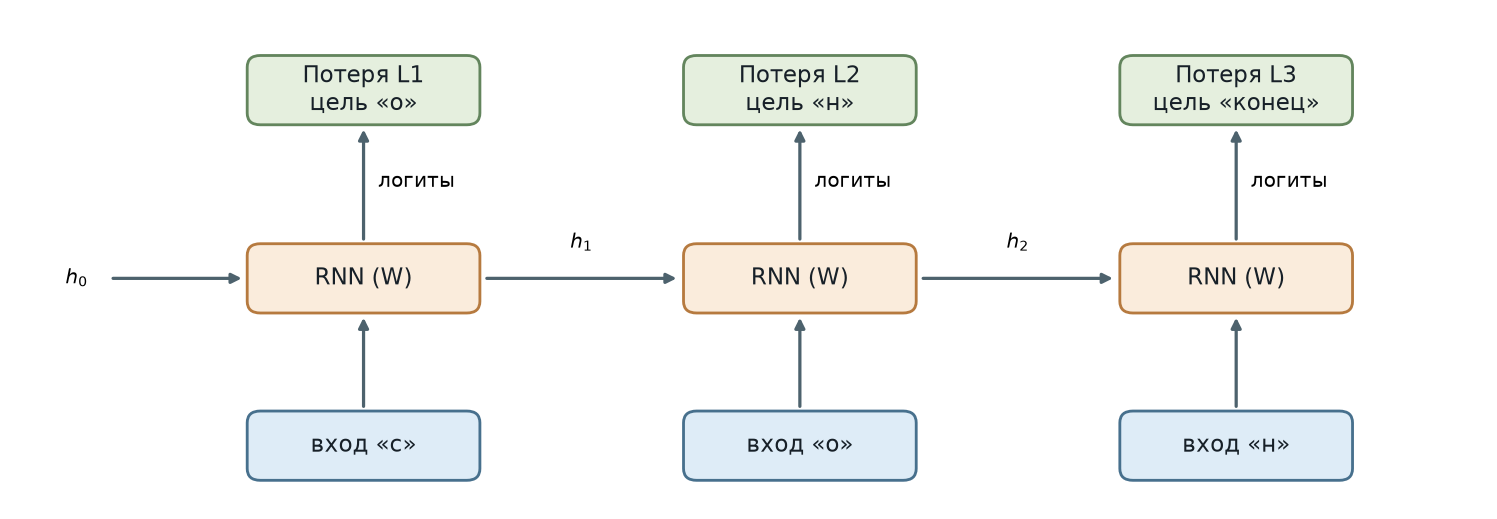

Для трёх целей средняя потеря $L=(L_1+L_2+L_3)/3$. При обратном проходе ошибка последнего прогноза влияет и на чтение первой буквы: от $L_3$ есть путь через $h_3,h_2,h_1$. Так как веса общие, градиент по $W$ суммирует вклады всех применений ячейки.

Оставим один скаляр в состоянии и один вес. Численно проверим, что один backward от средней потери даёт то же число, что и среднее трёх градиентов. Обратите внимание: производная третьей потери уже включает всю предшествующую цепочку.

In [ ]:
w = torch.tensor(.6, requires_grad=True)
h = torch.tensor(0.)
losses = []
for x_t, target in zip([.2, .7, -.3], [.7, -.3, .1]):
    h = torch.tanh(x_t + w*h)
    losses.append((h - target).square())
each = torch.stack([torch.autograd.grad(value, w, retain_graph=True)[0] for value in losses])
joint, = torch.autograd.grad(torch.stack(losses).mean(), w)
torch.testing.assert_close(each.mean(), joint)
print("Вклады трёх потерь:", each.tolist())
print("Градиент средней потери:", joint.item())

У первой потери производная по рекуррентному весу равна нулю: на первом шаге этот вес умножался на начальное состояние 0. Во втором и третьем шагах состояние уже зависит от прочитанного входа.

### Что остаётся от первого слова через 30 шагов?
«Книга, которую вчера после уроков принесли из библиотеки, **лежала** на столе». Чтобы выбрать окончание, нужно помнить число и род подлежащего через несколько промежуточных слов. Проверим на минимальной задаче: первым символом записали знак + или −, потом пришли одинаковые пустые входы. Может ли последний шаг различить два начала?

У скалярной RNN на пустом входе $h_t=\tanh(w h_{t-1})$. **При прямом проходе** сравним два состояния после разного количества шагов. **При обучении** посмотрим, какой сигнал от ошибки в конце дойдёт до начала. По цепному правилу
$$\frac{\partial h_T}{\partial h_0}=\prod_{t=1}^{T}w(1-h_t^2).$$
Если модули множителей меньше единицы, сигнал убывает с длиной цепочки. В насыщенной области tanh производная особенно мала. Большие множители, наоборот, могут дать всплеск градиента.

In [ ]:
delays = np.arange(31)
gap, sensitivity = [], []
for delay in delays:
    start = torch.tensor([-.8, .8], dtype=torch.float64, requires_grad=True)
    h = start
    for _ in range(delay):
        h = torch.tanh(.8 * h)
    gap.append((h[1] - h[0]).item())
    sensitivity.append(torch.autograd.grad(h[1], start)[0][1].item())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), constrained_layout=True)
for ax, values, title, label in zip(axes, [gap, sensitivity],
        ["Чтение: различимы ли два начала?", "Обучение: доходит ли поправка?"],
        ["Разность состояний", "Производная по первому состоянию"]):
    ax.semilogy(delays, values, "o-", ms=3, color=blue)
    ax.set(xlabel="Число пустых шагов", ylabel=label, title=title)
plt.show()

Это пример конкретных весов. Обученная RNN может удерживать информацию, но ей приходится подобрать одно преобразование и для записи нового входа, и для многократного сохранения старого. В LSTM появляется отдельный путь для памяти: старое значение умножается на вентиль забывания и складывается с новой записью. Если перенос близок к 1, а запись близка к 0, и число, и градиент по этому прямому пути сохраняются много шагов. При закрытом переносе память всё ещё может исчезнуть. Ограничение нормы градиента помогает при всплесках; исчезнувший сигнал оно не восстанавливает.

## 5. LSTM. Как сохранить информацию через много шагов?

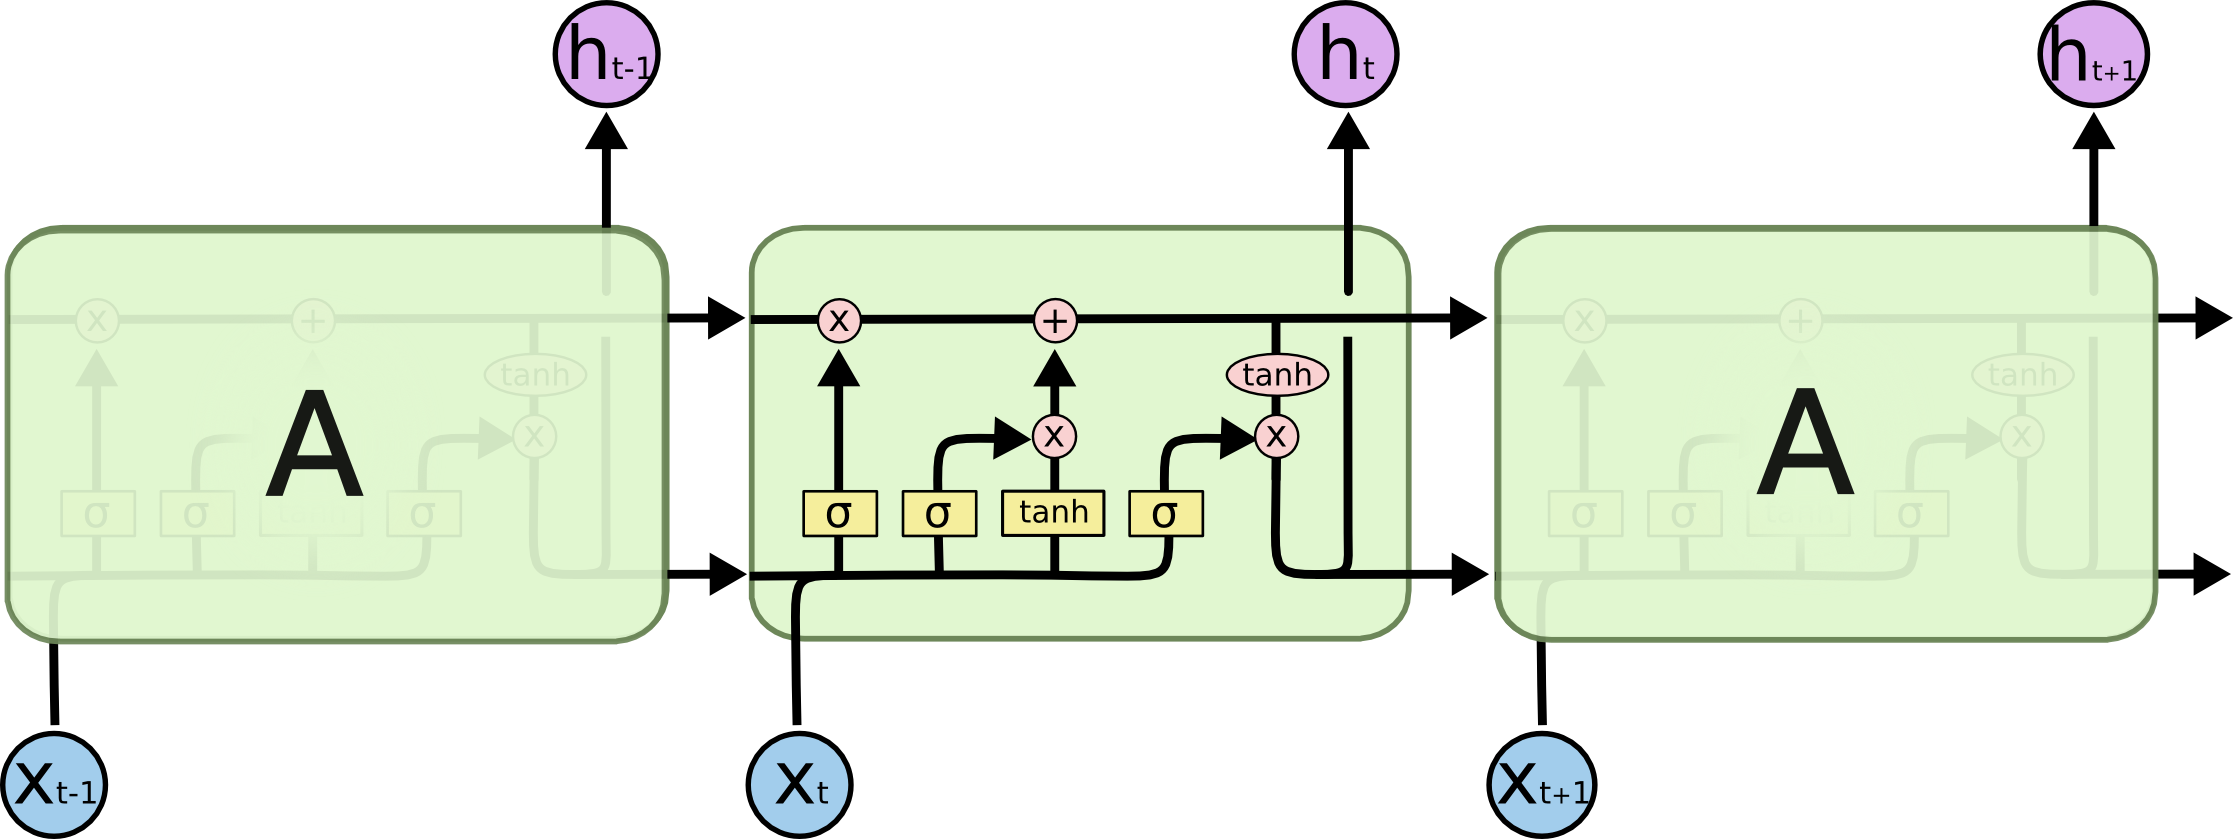

Начните со средней ячейки. Снизу приходит текущий вход, слева — прошлое состояние. Верхняя горизонтальная линия переносит память. Знак умножения на этой линии показывает, какую долю старого значения сохранить, а знак сложения — где прибавить новую запись. [Christopher Olah, Understanding LSTM Networks](https://colah.github.io/posts/2015-08-Understanding-LSTMs/)

В обычной RNN обратное распространение по времени перемножает производные всех промежуточных шагов. Даже в одной координате десять множителей по 0.5 оставляют лишь $0.5^{10}\approx0.001$ исходного сигнала. LSTM добавляет отдельную память $c_t$ с прямым путём переноса.

Соберём $z_t=[x_t,h_{t-1}]$. Четыре линейных преобразования дают
$$i_t=\sigma(W_i z_t+b_i),\quad f_t=\sigma(W_f z_t+b_f),\quad
g_t=\tanh(W_g z_t+b_g),\quad o_t=\sigma(W_o z_t+b_o).$$
Сначала переносим $f_t\odot c_{t-1}$ и добавляем запись $i_t\odot g_t$. Затем читаем долю новой памяти:
$$c_t=f_t\odot c_{t-1}+i_t\odot g_t,\qquad h_t=o_t\odot\tanh(c_t).$$
$\odot$ означает покоординатное умножение. При $f$ около единицы и маленьком $i$ запись долго сохраняется.

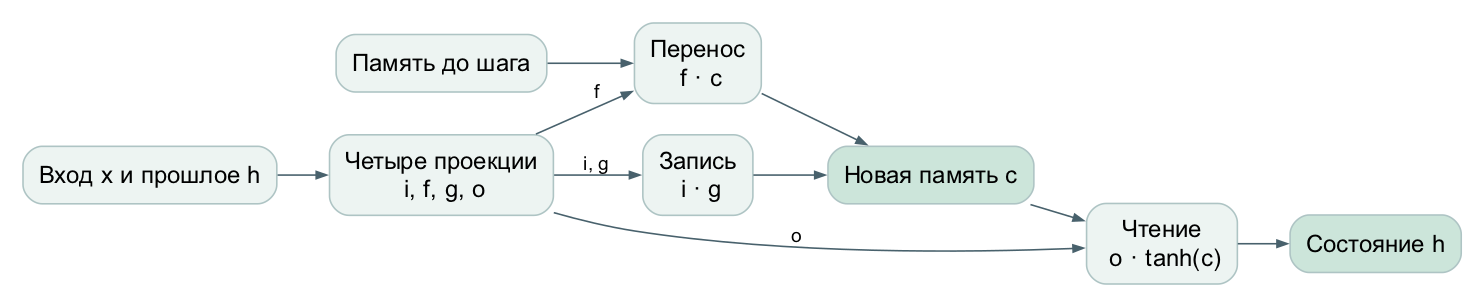

### Что произойдёт с одной записью в памяти?

Пусть в момент $t=0$ одна координата памяти содержит число $c_0=0.8$. Это произвольно выбранное значение активации. На следующих шагах новая запись равна нулю, а вентиль забывания сохраняет постоянную долю $f$ предыдущего значения. Тогда $c_1=f\cdot0.8$, $c_2=f^2\cdot0.8$ и $c_t=0.8f^t$. При $f=0.5$ первая пара шагов даёт $0.4$ и $0.2$. При $f=0.98$ — $0.784$ и примерно $0.768$.

In [ ]:
t = np.arange(13)
fig, ax = plt.subplots(figsize=(7, 3.5))
for f, color in [(0.5, red), (0.98, blue)]:
    ax.plot(t, .8 * f**t, "o-", label=f"Вентиль забывания f = {f}", color=color)
ax.set(xlabel="Шаги без новой записи", ylabel="Координата памяти c(t)", title="Начальная память 0.8 при двух значениях вентиля")
ax.legend()
fig.tight_layout()
plt.show()

## 6. Генерация. Как распределение превращается в строку?
В языковой модели голова вычисляет логиты $z=Wh_t+b$. После softmax получаем вероятность следующего токена:
$$p(k\mid x_{1:t})=\frac{\exp(z_k/T)}{\sum_j\exp(z_j/T)}.$$
При обучении обычно $T=1$. Для строки «кот» наблюдаем цели «о» после «к» и «т» после «ко». На генерации подаём префикс, выбираем следующий токен из распределения и подаём его обратно. Чем ниже положительная температура $T$, тем сильнее перевес лидера. Сравним при одних и тех же учебных логитах.

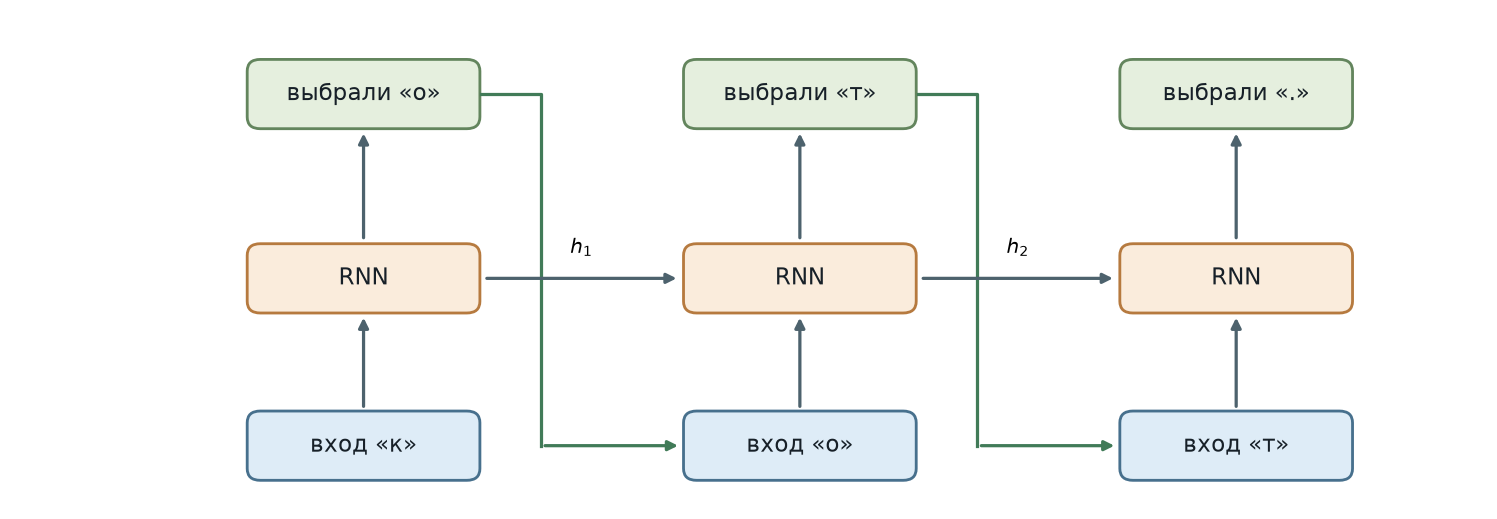

По горизонтальной стрелке передаётся скрытое состояние. По зелёной стрелке возвращается индекс выбранного символа: например, после «к» выбрали «о», и на следующем шаге сеть получит эмбеддинг «о». В примере ниже у максимального логита единственный лидер. При $T=0$ выбираем его напрямую. При очень большом $T$ вероятности всех четырёх символов стремятся к $1/4$.

In [ ]:
logits = torch.tensor([2., 1.4, .5, -.2])
letters = ["а", "о", "и", "перенос"]
fig, axes = plt.subplots(1, 5, figsize=(12, 3.1), sharey=True, constrained_layout=True)
for ax, temperature in zip(axes, [0, .5, 1, 1.8, 100000]):
    if temperature == 0:
        probs = F.one_hot(logits.argmax(), num_classes=len(letters)).float()
    else:
        probs = (logits / temperature).softmax(0)
    ax.bar(range(4), probs, color=[blue, "#719aaa", "#a7bec6", "#c9d8dc"])
    ax.axhline(.25, lw=.8, ls=":", color="grey")
    ax.set_xticks(range(4), letters, rotation=30)
    ax.set_title(f"T = {temperature:g}")
    ax.set_ylim(0, 1.06)
    assert torch.isclose(probs.sum(), torch.tensor(1.))
axes[0].set_ylabel("Вероятность следующего символа")
plt.show()

## 7. Как перевести фразу с помощью двух RNN?

В языковой модели для стихов был **один алфавит**. По индексу буквы входной слой выбирал строку таблицы эмбеддингов. На выходе линейный слой выдавал по логиту на букву того же алфавита, а softmax превращал логиты в вероятности. Индекс «о» в обоих местах обозначал «о». Входная таблица и выходной линейный слой при этом имели собственные обучаемые веса.

Для перевода заведём **два словаря**. Энкодер читает английские слова и использует английскую таблицу. Декодер читает русские слова и использует русскую таблицу. Размеры словарей могут различаться. Чтобы выбрать следующее русское слово, выходной слой выдаёт столько логитов, сколько элементов в русском словаре, включая служебные токены.

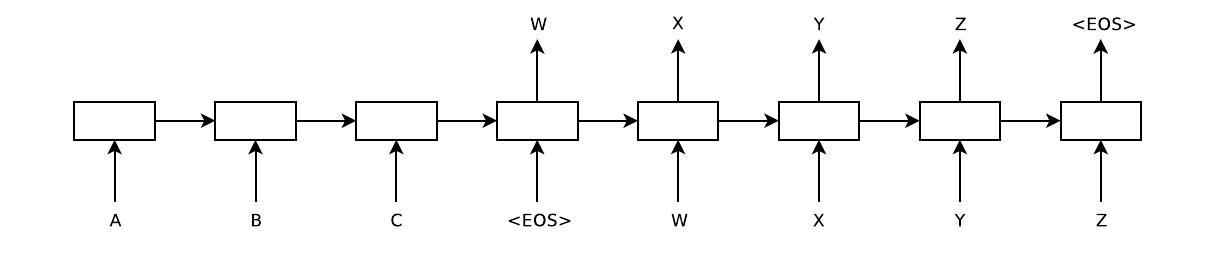

На рисунке авторов модель сначала читает A, B, C. После границы предложения появляются выходы W, X, Y, Z. Проследите букву W: она стоит сверху как первый результат и снизу как вход следующего шага. Прочитанный источник при этом остаётся прежним. [Sutskever, Vinyals, Le, Google, рис. 1](https://arxiv.org/pdf/1409.3215#page=2)

**Что передаётся между сетями?** В нашем переводчике без внимания энкодер возвращает последовательность скрытых векторов и пару финальных состояний $(h_S,c_S)$, где $S$ — длина исходной фразы. В декодер идёт только эта пара. Ею инициализируем его память и скрытое состояние до первого русского слова. Выходы отдельных шагов энкодера декодер напрямую не читает.

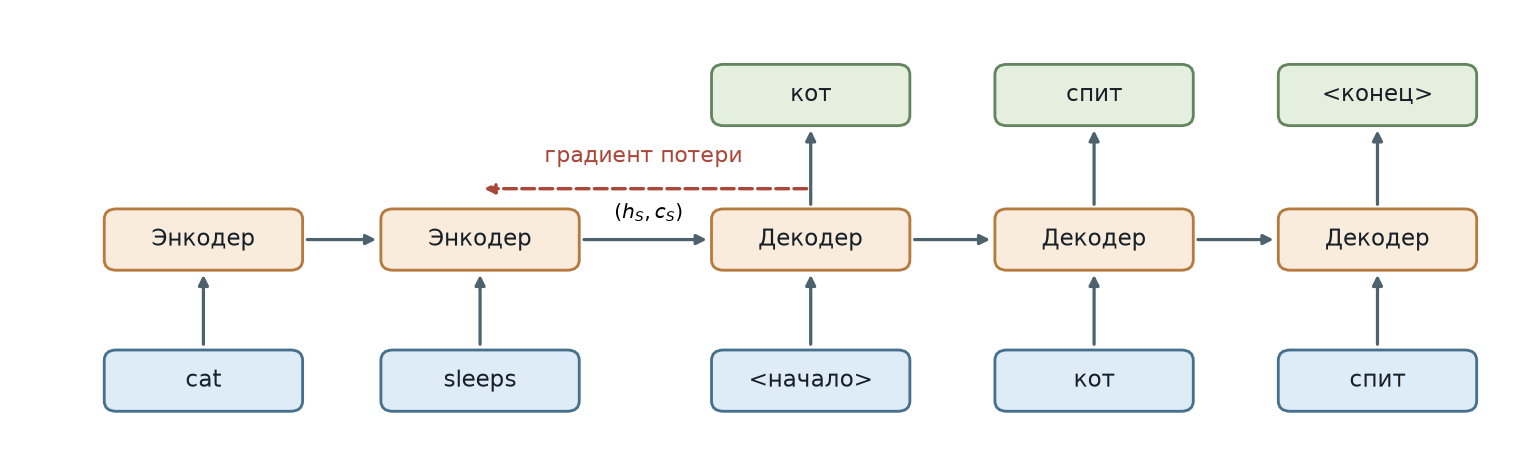

Стрелка вправо между сетями — передача значений. Пунктир влево — обратный проход при обучении. Потери всех русских шагов зависят от начального состояния декодера. Их производные по $h_S$ и $c_S$ возвращаются в последний шаг энкодера и дальше распространяются к предыдущим английским словам.

Обычно переводчик учится предсказывать **логиты по целевому словарю**. Есть и вариант с **непрерывным выходом**: декодер предсказывает вектор, при обучении его приближают к эталонному эмбеддингу слова, а при генерации выбирают ближайшее слово из целевой таблицы. Например, для фиксированных нормированных целевых векторов можно минимизировать $1-\cos(\hat v,v_y)$. В приведённом ниже переводчике используем логиты и кросс-энтропию. [Kumar и Tsvetkov, модели с непрерывным выходом](https://arxiv.org/abs/1812.04616)

### Какое слово дать декодеру после ошибки?

Исходный текст — **I see a cat**, эталон — **я вижу кота**. Энкодер один раз читает всю английскую фразу и передаёт своё финальное состояние декодеру. Строки таблицы — шаги декодера: он строит русский перевод, начиная с маркера начала. При обучении у нас есть весь перевод: на каждом следующем шаге подаём предыдущее **эталонное** слово и начисляем потерю за следующее. Это *teacher forcing*:
$$L=-\sum_t \log p(y_t\mid y_{<t},\text{источник}).$$
При переводе эталон недоступен. Пусть на втором шаге модель выбрала «слышу». Тогда на третьем шаге при обучении декодер получит эталонное «вижу», а при самостоятельном переводе — своё «слышу».

In [ ]:
source_en = "I see a cat"
reference_ru = "я вижу кота".split()
example_ru = "я слышу кота".split()  # Условный выбор декодера на втором шаге

print("Вход энкодера (EN):", source_en)
print("Эталонный перевод (RU):", " ".join(reference_ru))
print("Пример перевода с ошибкой (RU):", " ".join(example_ru))

decoder_steps = pd.DataFrame({
    "Обучение · вход": ["<начало>", *reference_ru],
    "Обучение · цель": [*reference_ru, "<конец>"],
    "Перевод · вход": ["<начало>", *example_ru],
    "Перевод · выбор": [*example_ru, "<конец>"],
}, index=pd.RangeIndex(1, len(reference_ru) + 2, name="Шаг декодера"))
decoder_steps

### Проследим перевод от английского входа до русского ответа

Обучим маленький переводчик на парах вроде **cat sleeps → кот спит**. Энкодеру даны оба английских слова. Декодеру на обучении даны `<начало>`, «кот», «спит», а целями служат «кот», «спит», `<конец>`. Затем уберём русский текст и дадим тот же английский вход. Проверим, сможет ли сеть воспроизвести перевод и собрать его для двух новых сочетаний знакомых слов.

In [ ]:
subjects = {"cat": "кот", "dog": "пёс", "bird": "птица"}
verbs = {"sleeps": "спит", "runs": "бежит", "eats": "ест", "sings": "поёт"}
src_vocab = list(subjects) + list(verbs)
dst_vocab = ["<начало>", "<конец>", *subjects.values(), *verbs.values()]
pairs = [(s, v) for s in subjects for v in verbs]
held_out = [("dog", "eats"), ("bird", "runs")]
training = [p for p in pairs if p not in held_out]

def source_ids(phrases):
    return torch.tensor([[src_vocab.index(w) for w in p] for p in phrases])

gold = torch.tensor([[dst_vocab.index(subjects[s]), dst_vocab.index(verbs[v]), 1]
                     for s,v in training])
previous = torch.cat([torch.zeros_like(gold[:, :1]), gold[:, :-1]], dim=1)
print("Словари:", len(src_vocab), "входных токенов и", len(dst_vocab), "выходных")
print("Вход энкодера:", " ".join(training[0]), "→", source_ids([training[0]]).tolist()[0])
pd.DataFrame({"вход декодера": [dst_vocab[i] for i in previous[0]],
              "правильный ответ": [dst_vocab[i] for i in gold[0]]})

In [ ]:
class Translator(nn.Module):
    def __init__(self):
        super().__init__()
        self.source = nn.Embedding(len(src_vocab), 16)
        self.target = nn.Embedding(len(dst_vocab), 16)
        self.encoder = nn.LSTM(16, 32, batch_first=True)
        self.decoder = nn.LSTM(16, 32, batch_first=True)
        self.head = nn.Linear(32, len(dst_vocab))

    def forward(self, source, history):
        _, (last_h, last_c) = self.encoder(self.source(source))
        states, _ = self.decoder(self.target(history), (last_h, last_c))
        return self.head(states)

torch.manual_seed(13)
torch.set_num_threads(2)
translator = Translator()
optimizer = torch.optim.Adam(translator.parameters(), lr=.025)
sources = source_ids(training)
for _ in range(180):
    logits = translator(sources, previous)
    loss = F.cross_entropy(logits.flatten(0, 1), gold.flatten())
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
print(f"Потеря на обучающих фразах: {loss.item():.4f}")

In [ ]:
# Эту же пару финальных состояний получает первый шаг декодера при переводе.
with torch.inference_mode():
    phrase = training[0]
    encoder_steps, (last_h, last_c) = translator.encoder(translator.source(source_ids([phrase])))
    start_token = torch.tensor([[dst_vocab.index("<начало>")]])
    first_step, _ = translator.decoder(translator.target(start_token), (last_h, last_c))
    next_word = translator.head(first_step[0, 0]).argmax().item()
print("Энкодер читает:", *phrase)
print("Выходы по словам:", tuple(encoder_steps.shape), "— сохраняем для просмотра")
print("В декодер переданы h и c:", tuple(last_h.shape), tuple(last_c.shape))
print("Первое предсказание после <начало>:", dst_vocab[next_word])

In [ ]:
@torch.inference_mode()
def translate(phrase):
    _, memory = translator.encoder(translator.source(source_ids([phrase])))
    token = torch.tensor([[0]])
    steps = []
    for t in range(5):
        state, memory = translator.decoder(translator.target(token), memory)
        probabilities = translator.head(state[0, 0]).softmax(dim=0)
        best = int(probabilities.argmax())
        steps.append((t+1, dst_vocab[token.item()], dst_vocab[best], round(probabilities[best].item(), 3)))
        if best == 1:
            break
        token = torch.tensor([[best]])
    return pd.DataFrame(steps, columns=["шаг", "вход", "выбор", "вероятность"])

for phrase in [training[0], *held_out]:
    print(" ".join(phrase), "→ эталон:", subjects[phrase[0]], verbs[phrase[1]])
    display(translate(phrase))

Высокая вероятность выбранного слова показывает уверенность декодера. Для оценки переноса сравните каждую новую фразу с эталоном **целиком**, включая конец. Десяти обучающих фраз достаточно для запоминания словосочетаний. Правильно перевести любую новую комбинацию этих слов — отдельное требование.

Чем длиннее исходная фраза, тем больше деталей энкодер должен сохранить в одной паре состояний фиксированного размера. Механизм внимания даёт декодеру доступ к состояниям **всех** позиций исходной фразы и позволяет заново взвешивать их на каждом шаге перевода. [Sutskever et al., Sequence to Sequence Learning](https://arxiv.org/abs/1409.3215) · [Bahdanau et al., Neural Machine Translation](https://arxiv.org/abs/1409.0473)

## 8. Сколько баллов получит перевод?

**Оригинал:** The train was ten minutes late. Сравним два ответа с одним русским эталоном. Считаем слова в нижнем регистре, без пунктуации.

| Вариант | Текст | Слов |
|---|---|---:|
| Эталон | поезд опоздал на десять минут | 5 |
| А | поезд опоздал на **двадцать** минут | 5 |
| Б | поезд прибыл с опозданием на десять минут | 7 |

В ответе А изменилось время опоздания. В ответе Б тот же смысл выражен семью словами. Какой ответ лучше передаёт оригинал? А у какого больше дословных совпадений?

### Сначала посчитаем совпадения

Униграмма — одно слово, биграмма — два соседних слова в том же порядке. Вот **все** биграммы. Жирным выделены те, которые нашлись в эталоне.

| Вариант | Биграммы в порядке появления |
|---|---|
| Эталон | поезд опоздал · опоздал на · на десять · десять минут |
| А | **поезд опоздал** · **опоздал на** · на двадцать · двадцать минут |
| Б | поезд прибыл · прибыл с · с опозданием · опозданием на · **на десять** · **десять минут** |

| Ответ | Что считаем | Совпало с эталоном | Совпадений $m_n$ | Всего в ответе $a_n$ | Всего в эталоне $r_n$ |
|---|---|---|---:|---:|---:|
| А | Слова | поезд, опоздал, на, минут | 4 | 5 | 5 |
| А | Биграммы | поезд опоздал, опоздал на | 2 | 4 | 4 |
| Б | Слова | поезд, на, десять, минут | 4 | 7 | 5 |
| Б | Биграммы | на десять, десять минут | 2 | 6 | 4 |

Повтор засчитывается столько раз, сколько он есть в обоих текстах. Если $C_A(g)$ и $C_R(g)$ — числа вхождений фрагмента $g$ в ответ и эталон, то $m_n=\sum_g\min(C_A(g),C_R(g))$. Например, если написать «поезд поезд», эталон подтвердит одно вхождение слова «поезд».

### BLEU: какая доля фрагментов ответа встретилась в эталоне?

Точность для фрагментов длины $n$ равна $p_n=m_n/a_n$. Для BLEU-2 берём геометрическое среднее точностей по словам и биграммам. Пусть $c$ — число слов в ответе, $r$ — число слов в эталоне. Множитель $BP$ штрафует короткий ответ:

$$BP=\begin{cases}1,&c\ge r,\\ \exp(1-r/c),&0<c<r.\end{cases}
\qquad \mathrm{BLEU}_2=BP\sqrt{p_1p_2}.$$

| Ответ | $p_1$ по словам | $p_2$ по биграммам | $BP$ | BLEU-2 |
|---|---:|---:|---:|---|
| А, 5 слов | $4/5$ | $2/4$ | $1$ | $\sqrt{(4/5)(2/4)}=0.632$ |
| Б, 7 слов | $4/7$ | $2/6$ | $1$ | $\sqrt{(4/7)(2/6)}=0.436$ |

У обоих ответов по четыре совпавших слова и по две совпавшие биграммы. У Б больше фрагментов в знаменателях, поэтому BLEU-2 у него ниже. Для сравнения, короткий ответ «на десять минут» целиком совпадает с концом эталона: $p_1=p_2=1$, но $BP=\exp(1-5/3)=0.513$.

**Как считают BLEU для системы перевода.** На корпусе складывают числители и знаменатели по предложениям *до деления*: $p_n=\sum_i m_{n,i}/\sum_i a_{n,i}$. Для $BP$ берут суммарные длины. Стандартный BLEU-4 с равными весами равен $BP\,(p_1p_2p_3p_4)^{1/4}$. Без сглаживания нулевая точность любого порядка даёт нулевой балл. У А и Б нет совпавших цепочек из четырёх слов, поэтому у обоих BLEU-4 равен нулю. При нескольких эталонах каждое совпадение ограничивают максимальным числом вхождений в одном эталоне, а для штрафа выбирают ближайшую к ответу длину, при равенстве — меньшую. [Papineni et al., BLEU](https://aclanthology.org/P02-1040/)

### ROUGE-1 и ROUGE-2: сколько фрагментов эталона покрыто?

Берём те же три числа из первой таблицы. **Точность** $P_n$ делит совпадения на длину списка в ответе, **полнота** $R_n$ — на длину списка в эталоне. **F1** объединяет обе оценки:

$$P_n=\frac{m_n}{a_n},\qquad R_n=\frac{m_n}{r_n},\qquad
F_{1,n}=\frac{2m_n}{a_n+r_n}.$$

| Ответ | Метрика | Точность $P$ | Полнота $R$ | F1 |
|---|---|---:|---:|---:|
| А | ROUGE-1 | $4/5=0.800$ | $4/5=0.800$ | $8/10=0.800$ |
| Б | ROUGE-1 | $4/7=0.571$ | $4/5=0.800$ | $8/12=0.667$ |
| А | ROUGE-2 | $2/4=0.500$ | $2/4=0.500$ | $4/8=0.500$ |
| Б | ROUGE-2 | $2/6=0.333$ | $2/4=0.500$ | $4/10=0.400$ |

По полноте ответы равны. По точности и F1 впереди А, хотя именно он сообщает неверное время. Поэтому в отчёте важно указать и порядок фрагментов, и вариант оценки: например, **ROUGE-2 recall**. [Lin, ROUGE](https://aclanthology.org/W04-1013/)

### ROUGE-L: сколько слов можно сохранить в том же порядке?

Найдём длиннейшую общую **подпоследовательность** ответа и эталона. Слова можно пропускать, переставлять нельзя. Обозначим её длину через $k$. Тогда $P_L=k/c$, $R_L=k/r$, а при равном весе точности и полноты $F_{1,L}=2k/(c+r)$.

| Ответ | Общая подпоследовательность | $k$ | $P_L$ | $R_L$ | ROUGE-L F1 |
|---|---|---:|---:|---:|---:|
| А | поезд → опоздал → на → минут | 4 | $4/5$ | $4/5$ | $8/(5+5)=0.800$ |
| Б | поезд → на → десять → минут | 4 | $4/7$ | $4/5$ | $8/(7+5)=0.667$ |

В Б можно пропустить «прибыл с опозданием» и продолжить совпадение со слова «на». Поэтому ROUGE-L засчитывает цепочку длины четыре, хотя ни одна биграмма со словом «поезд» в Б не совпала.

In [ ]:
from collections import Counter
from math import exp, sqrt

def ngram_counts(words, order):
    return Counter(zip(*(words[i:] for i in range(order))))

def overlap(reference, answer, order):
    ref = ngram_counts(reference, order)
    hyp = ngram_counts(answer, order)
    return sum((ref & hyp).values()), sum(hyp.values()), sum(ref.values())

def common_subsequence(reference, answer):
    previous = [0] * (len(answer) + 1)
    for word in reference:
        row = [0]
        for j, other in enumerate(answer, start=1):
            row.append(previous[j-1] + 1 if word == other else max(previous[j], row[-1]))
        previous = row
    return previous[-1]

def word_metrics(reference, answer):
    ref, hyp = reference.split(), answer.split()
    m1, c1, r1 = overlap(ref, hyp, 1)
    m2, c2, r2 = overlap(ref, hyp, 2)
    bp = min(1, exp(1 - r1 / c1)) if c1 else 0.
    bleu = bp * sqrt(m1 / c1 * m2 / c2) if c2 else 0.
    return [bleu, m1 / r1, m2 / r2, 2 * common_subsequence(ref, hyp) / (r1 + c1)]

reference = "поезд опоздал на десять минут"
answers = ["поезд опоздал на двадцать минут", "поезд прибыл с опозданием на десять минут"]
columns = ["BLEU-2", "ROUGE-1 R", "ROUGE-2 R", "ROUGE-L F1"]
rows = [word_metrics(reference, answer) for answer in answers]
np.testing.assert_allclose(rows, [[sqrt(2/5), 4/5, 2/4, 8/10],
                                  [sqrt(4/21), 4/5, 2/4, 8/12]])
pd.DataFrame(rows, index=answers, columns=columns).round(3)

### chrF. Что делать со словоформами?

В паре «ковре» и «ковра» совпали 4 из 5 букв и 3 из 4 соседних пар букв («ко», «ов», «вр»). На уровне целых слов совпадений ноль. **chrF** сравнивает символьные n-граммы. Для порядков обычно от 1 до 6 считаем точность и полноту совпадений с ограничением повторов, усредняем точности и полноты по порядкам и берём

$$F_\beta=(1+\beta^2)\frac{PR}{\beta^2P+R}.$$

При $\beta=2$ больший вес получает полнота. chrF даёт частичный балл близким написаниям. Это удобно для языков с богатой морфологией, хотя одна неверная буква бывает смыслоразличительной. [Popović, chrF](https://aclanthology.org/W15-3049/)

### Perplexity. Какую вероятность модель дала настоящему продолжению?

Для языковой модели берём отложенный текст и вероятность каждого настоящего следующего токена при его настоящем левом контексте. Пусть таких позиций $T$ после исключения padding. Тогда

$$\mathrm{PPL}=\exp\!\left(-\frac{1}{T}\sum_{t=1}^T\log p(x_t\mid x_{<t})\right).$$

Если правильная буква каждый раз получает вероятность $1/4$, perplexity равна 4. Меньше — лучше. Сравниваем модели на том же корпусе, при одинаковой токенизации и доступном контексте. На семинаре это даёт оценку по буквам. BLEU и ROUGE со следующим авторским четверостишием в качестве единственного эталона сильно штрафуют удачные альтернативные строки. Поэтому для свободной генерации рядом с perplexity читаем продолжения одного начала и смотрим, держатся ли тема, ритм и связность.

### Какой балл получил наш переводчик?

У двух отложенных фраз короткие двухсловные переводы. Посмотрим отдельно на совпадения слов и на порядок. Если в ответе верно только одно слово из двух, BLEU-2 без сглаживания будет нулевым, а ROUGE-1 покажет частичное совпадение.

In [ ]:
held_out_scores = []
for phrase in held_out:
    choices = translate(phrase)["выбор"].tolist()
    words = choices[:choices.index("<конец>")] if "<конец>" in choices else choices
    answer = " ".join(words)
    reference = f"{subjects[phrase[0]]} {verbs[phrase[1]]}"
    held_out_scores.append([" ".join(phrase), reference, answer, *word_metrics(reference, answer)])
pd.DataFrame(held_out_scores, columns=["Оригинал", "Эталон", "Перевод", *columns]).round(3)